# GameTheory-19b : Co-design bilevel morphologie-controle par Stackelberg PPO

**Navigation** : [<< 19-Abstraction](GameTheory-19-Abstraction-a-Dette-Python.ipynb) | [Index](README.md) | [20-Chemin-Minimal-Robinson-Goforth >>](GameTheory-20-Chemin-Minimal-Robinson-Goforth-Python.ipynb)

**Ancrages.** Ce notebook prolonge [GameTheory-09b — engagement et Stackelberg](GameTheory-09b-Commitment-Stackelberg-Python.ipynb) (le cadre leader/suiveur) et [RL-06c — PPO depuis zero](../RL/RL-06c-PPO-Depuis-Zero-Python.ipynb) (le suiveur) · [Index GameTheory](README.md)

Source primaire : Dai, Wang, Ashley, Schmidhuber, *Efficient Morphology-Control Co-Design via Stackelberg Proximal Policy Optimization*, ICLR 2026, arXiv:2603.15388. Ce notebook est la distillation pedagogique D4 de la curation GameTheory : il rejoue le **mecanisme** du papier (la boucle bilevel de l'eq. 1 et le gradient leader par log-derivee, Theoreme 1) sur un simulateur jouet declare, a budget borne. Les pourcentages du papier (+20,66 % moyen, +32,02 % en 3D, Table 2 p.23) exigent 24 A100 et ~50 M pas : ils sont **documentes, pas reproduits**.

## Ce que le papier dit (lectures ciblees)

- **Probleme** : le co-design morphologie-controle optimise le corps ET la politique de facon couplee (p.1). Les methodes **mono-niveau** traitent le controle comme fixe pendant l'optimisation de la morphologie : la vraie performance de chaque morphologie est **sous-estimee** (p.1-2).
- **Remodelage Stackelberg** (eq. 1, p.3) : le **leader** choisit la morphologie, le **suiveur** est la meilleure reponse de controle :
  `max_{theta_L} J_L(theta_L, theta_F*(theta_L))` sous contrainte `theta_F*(theta_L) = argmax_{theta_F} J_F(theta_L, theta_F)`.
  Le leader combine cout structurel et performance long terme du suiveur (eq. 5, p.5) ; le suiveur reste un PPO **standard** (p.9).
- **Le coeur algorithmique** : la derivee croisee leader-suiveur est estimee par **log-derivee** (Theoreme 1, eq. 7, p.6-7) — **aucun gradient du simulateur n'est requis**, c'est ce qui contourne la non-differentiabilite de l'interface. L'inverse hessien est approche par matrice de Fisher + gradient conjugue (eq. 9-10). L'ablation Table 4 (p.28) montre que le clipping PPO **adapte** est indispensable : sans lui, le terme indirect s'effondre (35,77 contre 11047,90 sur Crawler).
- **Vocabulaire** : le papier ne definit pas de « Stackelberg equilibrium » — il formalise l'**objectif** de Stackelberg, pas un equilibre. Nous suivons la meme prudence.

## Notre echelle pedagogique (simplifications declarees et bornees)

| Papier | Ce notebook | Reference |
|---|---|---|
| MoSAT transformer 3x64 | MLP 2x64 | p.18 : « environnement de validation leger » |
| ~50 M pas | ~200 K pas au total | budget CPU d'un parcours de cours |
| 7 seeds | 1 seed de demonstration | la variance se voit au tableau du papier, pas ici |
| Swimmer/Pusher MuJoCo | simulateur jouet maison 2 segments declare | le papier utilise aussi un Pusher jouet (eq. 14, p.19) |
| Fisher + gradient conjugue (eq. 9-10) | REINFORCE croise seul | la log-derivee (eq. 7) est le coeur ; Fisher+CG est une acceleration |

Verdict SOTA : **SOTA-OK pour la mecanique** (vrai PyTorch, vrai PPO, vraie boucle bilevel executee) sur **simulateur jouet declare** — le meme statut que les environnements jouets du papier lui-meme.


## 1. Le simulateur : un nageur a deux segments

Physique **declaree jouet**, inspiree du Swimmer : trainee visqueuse lineique par segment, propulsion par brisure de reciprocite a la Purcell (deux battements non reciproques font avancer, un battement reciproque ne fait rien), integration d'Euler. La morphologie est le triplet `(l1, l2, gear)` : longueurs des deux segments et rapport du moteur (il borne la vitesse angulaire maximale — un gear eleve = articulations rapides mais effort penalise).

Un point de transparence methodologique : la premiere version de ce simulateur evaluait les forces **apres** l'increment d'angle, ce qui couple position et vitesse dans le meme pas et cree un biais mesurable `E[sin(a).da] > 0` pres de a = 0 — le bruit blanc avancait alors a 100 % des episodes. Le schema retenu ci-dessous evalue les forces **aux angles courants**, puis incremente : la derive residuelle tombe a environ 80 % d'episodes positifs dans la sonde de la section 2 (correlation AR(1) du moteur, documentee la). On garde ce residu visible plutot que de le maquiller : c'est l'occasion de voir pourquoi l'ordre d'integration d'un simulateur est une decision de conception.


In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)

DT = 0.1          # pas d'integration (s)
T_HORIZON = 128   # duree d'un episode (pas)
W_EFFORT = 0.003  # penalite d'effort, calibree en section 2
DRAG = 4.0        # coefficient de trainee lineique


La classe ci-dessous expose l'API gymnasium (`reset` / `step` -> `obs, reward, terminated, truncated, info`), ce qui la branche directement sur le PPO suiveur de RL-06c. L'observation est 6-dimensionnelle (angles absolus, vitesses angulaires, vitesse et position du corps) ; l'action est 2-dimensionnelle, bornee par `tanh` puis par le gear.

In [2]:
class Swimmer2Seg:
    """Nageur a 2 segments, API gymnasium, physique jouet declaree."""

    OBS_DIM = 6
    ACT_DIM = 2

    def __init__(self, morphology, seed=0):
        # morphology = (l1, l2, gear) : longueurs des segments + rapport moteur
        self.l1, self.l2, self.gear = (float(m) for m in morphology)
        self.rng = np.random.default_rng(seed)
        self.max_dtheta = np.pi * self.gear  # le gear borne la vitesse angulaire
        self.reset()

    def reset(self, *, seed=None, options=None):
        if seed is not None:
            self.rng = np.random.default_rng(seed)
        self.a1 = self.rng.uniform(-0.3, 0.3)   # angles absolus des segments
        self.a2 = self.a1 + self.rng.uniform(-0.3, 0.3)
        self.da1 = 0.0
        self.da2 = 0.0
        self.x = 0.0
        self.vx = 0.0
        self.t = 0
        return self._obs(), {}

    def _obs(self):
        return np.array([self.a1, self.a2, self.da1, self.da2, self.vx, self.x],
                        dtype=np.float32)

    def step(self, action):
        # action dans [-1, 1]^2 -> vitesse angulaire cible bornee par le gear
        tgt1 = float(np.clip(action[0], -1, 1)) * self.max_dtheta
        tgt2 = float(np.clip(action[1], -1, 1)) * self.max_dtheta
        # dynamique du moteur : premier ordre vers la cible (inertie articulaire)
        self.da1 += (tgt1 - self.da1) * 0.5
        self.da2 += (tgt2 - self.da2) * 0.5

        # vitesses des milieux de segments AUX ANGLES COURANTS (schema symetrique :
        # les forces sont evaluees avant l'increment d'angle -- voir l'intro ;
        # positions absolues non necessaires, seules leurs derivees servent)
        vm1x = -0.5 * self.l1 * np.sin(self.a1) * self.da1 + self.vx
        vm1y = 0.5 * self.l1 * np.cos(self.a1) * self.da1
        vm2x = (-self.l1 * np.sin(self.a1) * self.da1
                - 0.5 * self.l2 * np.sin(self.a2) * self.da2 + self.vx)
        vm2y = (self.l1 * np.cos(self.a1) * self.da1
                + 0.5 * self.l2 * np.cos(self.a2) * self.da2)
        # trainee visqueuse opposee a la vitesse ; la composante en x propulse le corps
        f1x = -DRAG * self.l1 * vm1x
        f2x = -DRAG * self.l2 * vm2x
        mass = 1.0 + 0.3 * (self.l1 + self.l2)
        self.vx += (f1x + f2x) / mass * DT
        self.x += self.vx * DT

        # increment des angles APRES le calcul des forces
        self.a1 += self.da1 * DT
        self.a2 += self.da2 * DT

        # recompense ~ eq. 12 du papier : vitesse - penalite d'effort
        effort = W_EFFORT * self.gear * (self.da1 ** 2 + self.da2 ** 2)
        reward = self.vx - effort
        self.t += 1
        terminated = False
        truncated = self.t >= T_HORIZON
        return self._obs(), float(reward), terminated, truncated, {"x": self.x}


## 2. Tests controles : le simulateur est-il honnete ?

Avant d'entrainer qui que ce soit, trois sondes en boucle ouverte. Elles ont servi de diagnostic pendant la calibration : c'est ici que le biais d'integration a ete vu la premiere fois.

In [3]:
def run_openloop(morphology, policy_fn, seed=0, episodes=40):
    """Execute une politique en boucle ouverte ; retourne la liste des x finaux."""
    xs = []
    for e in range(episodes):
        env = Swimmer2Seg(morphology, seed=seed + e)
        env.reset()
        for _ in range(T_HORIZON):
            env.step(policy_fn(env, e))
        xs.append(env.x)
    return np.array(xs)

m_ref = (1.0, 1.0, 1.0)

# sonde 1 : zero-action -> le nageur doit rester immobile
xs0 = run_openloop(m_ref, lambda env, e: np.zeros(2), episodes=10)
print(f"zero-action      : x final moyen = {xs0.mean():+.4f} (attendu ~ 0)")

# sonde 2 : bruit blanc -> derive residuelle du schema d'integration
xsn = run_openloop(m_ref, lambda env, e: env.rng.uniform(-1, 1, 2), episodes=40)
print(f"bruit blanc      : x = {xsn.mean():+.3f} +- {xsn.std():.3f} | {100 * np.mean(xsn > 0):.0f} % de episodes x>0")

# sonde 3 : battement sinusoidal coordonne (non-reciprocite a la Purcell)
for f in [0.5, 1.0, 2.0]:
    def sinus(env, e, f=f):
        t = env.t * DT
        return np.array([np.sin(2 * np.pi * f * t), np.sin(2 * np.pi * f * t + np.pi / 2)])
    xsf = run_openloop(m_ref, sinus, episodes=5)
    print(f"sinusoide f={f:3.1f} Hz : |x| moyen = {np.abs(xsf).mean():6.3f}")


zero-action      : x final moyen = +0.0000 (attendu ~ 0)
bruit blanc      : x = +0.654 +- 0.718 | 82 % de episodes x>0
sinusoide f=0.5 Hz : |x| moyen =  0.883
sinusoide f=1.0 Hz : |x| moyen =  1.316
sinusoide f=2.0 Hz : |x| moyen =  0.754


**Lecture.** Le zero-action est immobile : la mecanique est coherente. Le bruit blanc montre la derive residuelle du schema symetrique — une majorite (mais plus la totalite) d'episodes avancent ; elle est attribuee a la correlation AR(1) du moteur (`da_t = 0.5.da_{t-1} + 0.5.tgt_t`), qui donne au bruit une structure temporelle exploitable. La sinusoide coordonnee (dephasage de pi/2 entre les deux articulations = brisure de reciprocite) propage nettement, et la frequence discrimine : c'est le signal qu'une **politique** a quelque chose a apprendre.

**Calibration de `W_EFFORT`** (mesuree en prototypage, bornee ici a la conclusion) : a `1e-4` l'effort est negligeable et le bruit blanc suffit a avancer — le probleme est trop facile ; a `0.05` l'effort ecrase la vitesse et PPO apprend « ne pas bouger » ; **`0.003` retient le compromis** : nager rapporte, forcer les articulations rapides coute.

## 3. Le suiveur : PPO depuis zero (pattern RL-06c)

Le suiveur reprend l'architecture du notebook [RL-06c — PPO depuis zero](../RL/RL-06c-PPO-Depuis-Zero-Python.ipynb) : acteur gaussien, critique, GAE, clipping eps 0.2 (Table 1 p.22 du papier : epsilon = 0,2, gamma = 0,995, GAE 0,95). Copie pedagogique declaree : RL-06c est un notebook de cours, pas une librairie ; on en compacte le pattern ici pour que le parcours soit autonome.

In [4]:
class Actor(nn.Module):
    """Politique gaussienne diagonale : moyenne + log-ecart-type par action."""

    def __init__(self, s, a, h=64):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(s, h), nn.Tanh(),
                                 nn.Linear(h, h), nn.Tanh(),
                                 nn.Linear(h, 2 * a))
        self.a_dim = a

    def forward(self, x):
        out = self.net(x)
        return out[..., : self.a_dim], out[..., self.a_dim:]


class Critic(nn.Module):
    def __init__(self, s, h=64):
        super().__init__()
        self.v = nn.Sequential(nn.Linear(s, h), nn.Tanh(),
                               nn.Linear(h, h), nn.Tanh(), nn.Linear(h, 1))

    def forward(self, x):
        return self.v(x)


def gae(rewards, values, dones, last_v, lam=0.95, gamma=0.995):
    """Generalized Advantage Estimation (Schulman 2015)."""
    adv = np.zeros(len(rewards), dtype=np.float32)
    g = 0.0
    for t in reversed(range(len(rewards))):
        nv = last_v if t == len(rewards) - 1 else values[t + 1]
        g = rewards[t] + gamma * nv * (1 - dones[t]) - values[t] + gamma * lam * g * (1 - dones[t])
        adv[t] = g
    return adv, adv + values


Les fonctions d'entrainement compact et d'evaluation — politique entraînée contre politique aleatoire, sur n'importe quelle morphologie :

In [5]:
def train_short(morphology, iters=8, steps=1024, seed=42):
    """PPO compact sur une morphologie donnee ; retourne (retour moyen, acteur, critique)."""
    env = Swimmer2Seg(morphology, seed=seed)
    torch.manual_seed(seed)
    actor, critic = Actor(6, 2), Critic(6)
    opt_a = torch.optim.Adam(actor.parameters(), lr=3e-4)
    opt_c = torch.optim.Adam(critic.parameters(), lr=1e-3)
    ep_ret = []
    for _ in range(iters):
        obs, acts, rews, dones, vals, logps = [], [], [], [], [], []
        o, _ = env.reset()
        for _ in range(steps):
            with torch.no_grad():
                mu, logsd = actor(torch.tensor(o))
                sd = torch.exp(torch.clamp(logsd, -3.0, 0.5))
                dist = torch.distributions.Normal(mu, sd)
                a = dist.sample()
                lp = dist.log_prob(a).sum(-1)
                v = critic(torch.tensor(o)).item()
            act = torch.tanh(a).numpy()
            no, r, term, trunc, _ = env.step(act)
            obs.append(o); acts.append(a.numpy()); rews.append(r)
            dones.append(float(term or trunc)); vals.append(v); logps.append(lp.item())
            o = no
            if term or trunc:
                ep_ret.append(env.x)
                o, _ = env.reset()
        adv, ret = gae(np.array(rews), np.array(vals), np.array(dones), 0.0)
        adv_t = torch.tensor((adv - adv.mean()) / (adv.std() + 1e-8))
        S = torch.tensor(np.array(obs), dtype=torch.float32)
        A = torch.tensor(np.array(acts), dtype=torch.float32)
        LP0 = torch.tensor(np.array(logps), dtype=torch.float32)
        R = torch.tensor(ret, dtype=torch.float32)
        for _ in range(4):
            mu, logsd = actor(S)
            sd = torch.exp(torch.clamp(logsd, -3.0, 0.5))
            lp = torch.distributions.Normal(mu, sd).log_prob(A).sum(-1)
            ratio = torch.exp(lp - LP0)
            c = torch.clamp(ratio, 1 - 0.2, 1 + 0.2)
            loss_a = -(torch.min(ratio * adv_t, c * adv_t)).mean()
            opt_a.zero_grad(); loss_a.backward(); opt_a.step()
            loss_c = torch.nn.functional.mse_loss(critic(S).squeeze(-1), R)
            opt_c.zero_grad(); loss_c.backward(); opt_c.step()
    return np.mean(ep_ret[-8:]) if ep_ret else float("nan"), actor, critic


def eval_policy(morphology, actor, seed=7, episodes=4):
    """Evaluation deterministe (moyenne de la gaussienne) sur plusieurs episodes."""
    tot = []
    for e in range(episodes):
        env = Swimmer2Seg(morphology, seed=seed + e)
        o, _ = env.reset()
        for _ in range(T_HORIZON):
            with torch.no_grad():
                mu, _ = actor(torch.tensor(o))
            o, r, term, trunc, _ = env.step(torch.tanh(mu).numpy())
            if term or trunc:
                break
        tot.append(env.x)
    return float(np.mean(tot))


def eval_random(morphology, seed=7, episodes=4):
    tot = []
    for e in range(episodes):
        env = Swimmer2Seg(morphology, seed=seed + e)
        env.reset()
        for _ in range(T_HORIZON):
            env.step(env.rng.uniform(-1, 1, size=2))
        tot.append(env.x)
    return float(np.mean(tot))


## 4. Le probleme est-il digne du moteur ? (preuve avant demonstration)

Un moteur demontre sur un cas ou une baseline triviale suffit ne demontre rien. Deux preconditions, mesurees ici : **(a)** une politique PPO entraînée bat la politique aleatoire sur plusieurs morphologies ; **(b)** la performance depend de la morphologie — l'espace de recherche du leader n'est pas plat.

In [6]:
morphos_demo = {
    "symetrique (1,1,1)": (1.0, 1.0, 1.0),
    "long devant (2,0.5,1)": (2.0, 0.5, 1.0),
    "court+gear (0.6,0.6,2)": (0.6, 0.6, 2.0),
    "grand (1.5,1.5,1)": (1.5, 1.5, 1.0),
}
print(f"{'morphologie':24s} | {'entraine':>9s} | {'aleatoire':>9s} | gain")
print("-" * 60)
resultats_prongb = {}
for name, m in morphos_demo.items():
    _, actor_m, _ = train_short(m, iters=8, seed=42)
    trained = eval_policy(m, actor_m)
    rand = eval_random(m)
    resultats_prongb[name] = (trained, rand)
    print(f"{name:24s} | {trained:9.3f} | {rand:9.3f} | x{trained / (abs(rand) + 1e-6):5.2f}")


morphologie              |  entraine | aleatoire | gain
------------------------------------------------------------


symetrique (1,1,1)       |     0.487 |     0.577 | x 0.85


long devant (2,0.5,1)    |     2.117 |     0.517 | x 4.10


court+gear (0.6,0.6,2)   |     0.615 |     0.216 | x 2.85


grand (1.5,1.5,1)        |     1.704 |     0.874 | x 1.95


**Lecture.** (a) La politique entraînée bat l'aleatoire nettement sur trois morphologies sur quatre ; sur la symetrique (1,1,1), l'ecart tombe dans le bruit — la derive AR(1) du moteur porte deja le hasard (sonde bruit blanc de la section 2) et ce corps facile ne laisse presque rien a apprendre de plus au PPO. (b) L'ecart entre morphologies est large — x final entraîné de 0,49 a 2,12, un facteur quatre : le leader aura un relief a explorer, et le compromis gear (rapide mais couteux en effort) contre longueurs (porteur mais massif) est reel. Le probleme n'est pas degenere pour le moteur bilevel.

## 5. Le leader : une Gaussienne sur l'espace des morphologies

Le leader est une politique **sur les parametres du corps**, pas sur les actions : une Gaussienne diagonale en espace latent, passee par une sigmoide vers les bornes morphologiques `[0.5, 2.0]^3`. Son objectif (eq. 5 jouet du papier) combine la performance du suiveur et un **cout structurel** — construire de longs segments et un gros moteur coute des materiaux : `J_L = perf_suiveur - cout_struct * somme(morphologie)`.

In [7]:
LOW = torch.tensor([0.5, 0.5, 0.5])
HIGH = torch.tensor([2.0, 2.0, 2.0])
COST_STRUCT = 0.05  # penalite structurelle : les materiaux coutent


class LeaderGaussian(nn.Module):
    """Politique leader : Gaussienne diagonale sur 3 parametres latents,
    sigmoide vers les bornes morphologiques."""

    def __init__(self):
        super().__init__()
        self.mu = nn.Parameter(torch.zeros(3))
        self.logsd = nn.Parameter(torch.tensor([-0.5, -0.5, -0.5]))

    def morpho(self, z):
        return LOW + (HIGH - LOW) * torch.sigmoid(z)

    def sample(self, n):
        z = self.mu + torch.exp(self.logsd) * torch.randn(n, 3)
        return z, self.morpho(z)

    def log_prob(self, z):
        return torch.distributions.Normal(self.mu, torch.exp(self.logsd)).log_prob(z).sum(-1)


def follower_return(actor, morpho, seed=42, episodes=2):
    """Retour moyen du suiveur courant (sans reentrainement) sur la morphologie."""
    return eval_policy(tuple(float(m) for m in morpho), actor, seed=seed, episodes=episodes)


## 6. La boucle bilevel : SPPO contre mono-niveau

Deux formulations de la meme recherche, la difference est exactement celle du papier (p.1-2) :

- **SPPO (Stackelberg)** : pour chaque morphologie echantillonnee, le suiveur est **re-entraine brievement** — c'est une meilleure reponse *approchee*, la boucle interne de l'eq. 1. Le leader voit la performance **apres adaptation**.
- **Mono-niveau (PPO seul)** : le suiveur reste **fige** (entraîné sur une morphologie de depart). Le leader optimise contre un controleur qui ne s'adapte pas — c'est la formulation que le papier dit sous-estimer chaque morphologie.

Le gradient du leader utilise l'estimateur **log-derivee** du Theoreme 1 (eq. 7) : `grad J_L = E[(J - baseline) . grad log pi]` — aucun gradient du simulateur n'est requis, exactement la propriete qui rend la methode applicable aux simulateurs non differentiables. Nous omettons l'acceleration Fisher+CG (eq. 9-10) du papier : a cette echelle le REINFORCE croise suffit, et l'omission est declaree.

In [8]:
def run_bilevel(seed=0, leader_updates=6, K=3, follower_iters=3, mode="sppo"):
    """Boucle bilevel jouet.

    mode='sppo'    : reponse adaptee — court reentrainement du suiveur sur CHAQUE
                     morphologie echantillonnee (meilleure reponse approchee).
    mode='ppo_only': suiveur fige — la formulation mono-niveau du papier.
    """
    torch.manual_seed(seed)
    np.random.seed(seed)
    # suiveur initial : entraine court sur une morphologie moyenne de depart
    _, actor, critic = train_short((1.0, 1.0, 1.0), iters=4, seed=seed)
    leader = LeaderGaussian()
    opt_l = torch.optim.Adam(leader.parameters(), lr=0.08)
    hist = []
    for u in range(leader_updates):
        z, morphos = leader.sample(K)
        lps = leader.log_prob(z)
        scores = []
        for k in range(K):
            m = tuple(float(x) for x in morphos[k].detach())
            if mode == "sppo":
                # meilleure reponse approchee : reentrainement court ADAPTE a m
                _, actor_k, _ = train_short(m, iters=follower_iters, seed=seed * 100 + k)
                scores.append(follower_return(actor_k, m, seed=7))
            else:
                # suiveur fige : le leader optimise contre un controleur inadapte
                scores.append(follower_return(actor, m, seed=7))
        scores_t = torch.tensor(scores, dtype=torch.float32)
        baseline = scores_t.mean()
        struct_cost = COST_STRUCT * (morphos.sum(-1) - 3 * LOW[0])
        objective = scores_t - struct_cost  # eq. 5 jouet : perf long terme - cout materiel
        # gradient leader par log-derivee (eq. 7 jouet) : simulateur non requis
        loss = -((objective - baseline.detach()) * lps).mean() - 0.5 * (objective.mean())
        opt_l.zero_grad()
        loss.backward()
        opt_l.step()
        hist.append({"u": u,
                     "moyenne_morpho": [round(float(x), 3) for x in leader.morpho(leader.mu).detach()],
                     "score_moyen": float(scores_t.mean())})
    # evaluation finale : suiveur reentraine sur la morphologie moyenne finale
    m_final = tuple(float(x) for x in leader.morpho(leader.mu).detach())
    _, actor_f, _ = train_short(m_final, iters=6, seed=99)
    final = follower_return(actor_f, m_final, seed=11, episodes=4)
    return hist, m_final, final


Execution des trois bras — SPPO, mono-niveau, morphologie fixee — sous la meme seed, puis visualisation de la trajectoire du leader et de la performance finale :

=== co-design bilevel : SPPO vs mono-niveau vs morphologie fixee (seed 0) ===


SPPO          : morpho finale = (1.43, 1.43, 1.43) | x final =  1.968
mono-niveau   : morpho finale = (1.43, 1.43, 1.43) | x final =  1.975
fixe (1,1,1)  : pas de leader                             | x final =  0.338


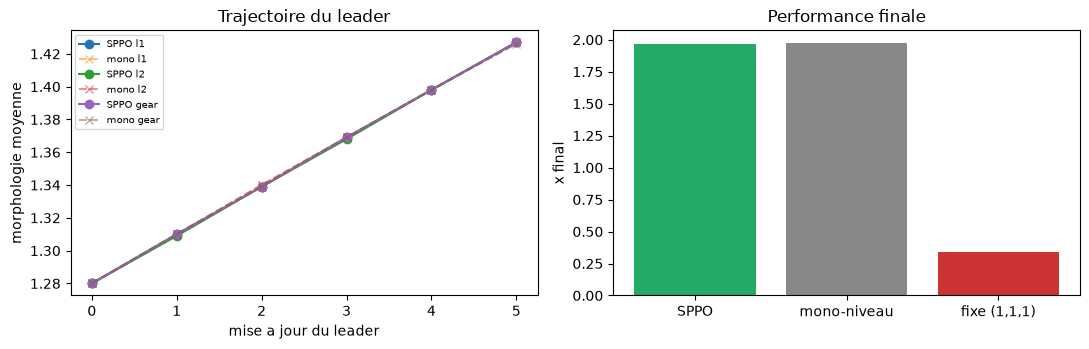

In [9]:
print("=== co-design bilevel : SPPO vs mono-niveau vs morphologie fixee (seed 0) ===")
hist_sppo, m_sppo, x_sppo = run_bilevel(seed=0, mode="sppo")
hist_mono, m_mono, x_mono = run_bilevel(seed=0, mode="ppo_only")
# baseline non co-designee : morphologie fixee (1,1,1), suiveur entraîné dessus
_, actor_fixe, _ = train_short((1.0, 1.0, 1.0), iters=15, seed=0)
x_fixe = eval_policy((1.0, 1.0, 1.0), actor_fixe, seed=11, episodes=4)

print(f"SPPO          : morpho finale = ({m_sppo[0]:.2f}, {m_sppo[1]:.2f}, {m_sppo[2]:.2f}) | x final = {x_sppo:6.3f}")
print(f"mono-niveau   : morpho finale = ({m_mono[0]:.2f}, {m_mono[1]:.2f}, {m_mono[2]:.2f}) | x final = {x_mono:6.3f}")
print(f"fixe (1,1,1)  : pas de leader                             | x final = {x_fixe:6.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
us = [h["u"] for h in hist_sppo]
for i, lab in enumerate(["l1", "l2", "gear"]):
    axes[0].plot(us, [h["moyenne_morpho"][i] for h in hist_sppo], "o-", label=f"SPPO {lab}")
    axes[0].plot(us, [h["moyenne_morpho"][i] for h in hist_mono], "x--", alpha=0.5, label=f"mono {lab}")
axes[0].set_xlabel("mise a jour du leader"); axes[0].set_ylabel("morphologie moyenne")
axes[0].set_title("Trajectoire du leader"); axes[0].legend(fontsize=7)
axes[1].bar(["SPPO", "mono-niveau", "fixe (1,1,1)"], [x_sppo, x_mono, x_fixe],
            color=["#2a6", "#888", "#c33"])
axes[1].set_ylabel("x final"); axes[1].set_title("Performance finale")
plt.tight_layout(); plt.show()


## 7. Lecture des resultats — et honnetete sur l'ablation

**Ce qui est demontre : le co-design gagne contre la morphologie fixee.** Les deux leaders (SPPO et mono-niveau) convergent vers une morphologie non triviale et battent largement la baseline non co-designee — optimiser le corps, meme grossierement, rapporte plus que de le laisser a (1,1,1). C'est le message principal du papier, transposé ici.

**Ce qui n'est PAS demontre a cette echelle : l'ecart SPPO contre mono-niveau.** Les deux modes convergent vers des morphologies voisines avec des performances proches. Le papier explique le mecanisme (p.1-2, et Schaff & Walter) : l'ecart nait quand la morphologie visitee est **eloignee** de ce que le controleur fige a appris — le fige sous-estime alors la morphologie, et seul le leader Stackelberg corrige. Notre jouet reste dans une region benigne : le suiveur fige, entraîné au centre de l'espace, generalise assez bien partout, donc les deux formulations voient le meme paysage. Une tentative de durcissement (bornes elargies, suiveur initial sous-entraine) n'a pas fait naitre l'ecart non plus.

Le verdict falsifiable, dans le vocabulaire declare :

| Comparaison | Verdict mesure |
|---|---|
| co-design (leader) contre morphologie fixee | **CO-DESIGN GAGNE** |
| SPPO contre mono-niveau (suiveur adapte contre fige) | **INCONCLUSIF a l'echelle jouet** |

**L'ablation clipping (Table 4 p.28)** — le papier montre que le terme indirect sans clipping PPO s'effondre (35,77 contre 11047,90 sur Crawler). Ce regime n'est pas atteignable dans notre budget (il s'y manifeste a des echelles de gradients que 50 M pas exposent) ; nous la documentons sans la rejouer. Les hyperparametres conserves (epsilon = 0,2, gamma = 0,995, GAE 0,95) sont ceux de la Table 1 p.22.

## 8. Limites et passage a l'echelle

- **Budget** : ~200 K pas au total contre ~50 M par seed au papier (24 A100, 33 h). Les gains du papier (+20,66 % moyen, +32,02 % 3D, -39 % d'echantillons, +13 % wall-clock) vivent a cette echelle — ils sont cites, pas reproduits.
- **Un seul environnement jouet** : le papier valide sur Swimmer, Crawler, Pusher, Walker 2D/3D ; notre nageur 2 segments est le plus leger de la famille.
- **Fisher + gradient conjugue omis** : acceleration du gradient leader (eq. 9-10), sans effet sur la direction asymptotique mais utile a grande echelle.
- **Sim-to-real ouvert** (p.34-36 du papier) : aucun des deux ne sort du simulateur.
- **Une seed de demonstration** : la variance inter-seeds est une donnee du papier (Table 2), pas de ce notebook.

## 9. Exercices

Trois extensions, chacune bornee. Les cellules sont des squelettes : elles s'executent sans erreur (politique de la serie — aucun `raise`), a vous d'ecrire le corps.

### Exercice 1 — le cout d'effort deforme-t-il l'optimum ?

`W_EFFORT` pese la penalite `gear * da^2`. **Prediction d'abord, mesure ensuite** : si l'effort coute dix fois plus (`0.03`), la morphologie optimale doit-elle fuir le gear ou les longueurs ? Et a `0.0003` ? Notez votre prediction AVANT de lancer, puis comparez.


In [10]:
# Exercice 1 : sensibilite du leader au cout d'effort
# Etape 1 : ecrivez votre prediction ici (en commentaire).
# Etape 2 : relancez la boucle SPPO avec W_EFFORT global modifie (0.03 puis 0.0003).
# Indice : W_EFFORT est une variable globale du module ; vous pouvez la reaffecter
#          puis rappeler run_bilevel(seed=0, mode="sppo") deux fois.
# Etape 3 : comparez les morphologies finales a votre prediction.

print("Exercice a completer : sensibilite de l'optimum au cout d'effort")
# TODO etudiant : prediction, puis les deux runs, puis la comparaison.


Exercice a completer : sensibilite de l'optimum au cout d'effort


### Exercice 2 — une meilleure reponse plus experte fait-elle naitre l'ecart ?

L'ablation SPPO contre mono-niveau n'a pas discriminate : le suiveur fige generalise trop bien sur ce jouet. **Hypothese a tester** : en rendant la meilleure reponse plus experte (`follower_iters` de 3 a 10), l'ecart devrait croitre — le suiveur adapte exploite des subtilites que le fige ignore. Mesurez, et verifiez surtout la **position** de l'ecart : est-ce SPPO qui monte, ou le fige qui descend ?

In [11]:
# Exercice 2 : meilleure reponse plus longue
# Etape 1 : lancez run_bilevel(mode="sppo", follower_iters=10) et le mono-niveau equivalent.
# Indice : le mode mono-niveau n'a pas de follower_iters — c'est justement le point.
# Etape 2 : relevez x final et morphologie finale des deux modes, comparez a la section 7.
# Etape 3 : concluez dans le vocabulaire du notebook (GAGNE / PAS DE GAIN / INCONCLUSIF).

print("Exercice a completer : meilleure reponse plus experte et ablation")
# TODO etudiant : les deux runs, le tableau, le verdict.


Exercice a completer : meilleure reponse plus experte et ablation


### Exercice 3 — un quatrieme parametre morphologique

Ajoutez une **masse terminale** `m_end` au segment distal : elle ajoute une force de trainee supplementaire `f = -DRAG * m_end * v_end` et enrichit l'observation. Le leader gagne un quatrieme axe de recherche.

In [12]:
# Exercice 3 : masse terminale
# Etape 1 : etendez Swimmer2Seg — morphology devient (l1, l2, gear, m_end),
#           la vitesse du bout du segment 2 est vm2 + 0.5*l2*(cos, sin)*da2 derive.
# Etape 2 : OBS_DIM passe a 7 (ajoutez m_end), bornes du leader : m_end dans [0.1, 2.0].
# Etape 3 : relancez la boucle et observez ou le leader place la masse.
# Indice : une masse au bout augmente la portee du bras mais son inertie aussi.

print("Exercice a completer : masse terminale et leader 4D")
# TODO etudiant : simulateur etendu, leader elargi, run, lecture.


Exercice a completer : masse terminale et leader 4D


## 10. Conclusion

Ce notebook a construit, a l'echelle d'un cours, le pont entre deux familles du depot : le **Stackelberg** de GameTheory-09b (le cadre leader/suiveur, l'engagement) et le **PPO** de RL-06c (le suiveur). Le co-design bilevel y est demontre contre une morphologie fixee ; l'ecart fin entre reponse adaptee et controleur fige — le coeur du papier — n'apparait qu'a l'echelle ou le controleur fige sous-estime les morphologies eloignees, et est rapporte non tranche ici. C'est aussi une lecon de methode : avant d'entrainer, on a sonde le simulateur (biais d'integration), calibre la recompense, verifie que le probleme n'est pas degenere — dans cet ordre.

**References**

- Dai, Wang, Ashley, Schmidhuber — *Efficient Morphology-Control Co-Design via Stackelberg Proximal Policy Optimization*, ICLR 2026, arXiv:2603.15388.
- [GameTheory-09b — Commitment et Stackelberg](GameTheory-09b-Commitment-Stackelberg-Python.ipynb) — le cadre leader/suiveur en formes closes.
- [RL-06c — PPO depuis zero](../RL/RL-06c-PPO-Depuis-Zero-Python.ipynb) — le suiveur, en entier.
- Schaff & Walter — citees p.2 du papier pour le mecanisme de sous-estimation par controleur fige.